# EDA + Logistic Regression on the Adult Income dataset



In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plt.style.use("seaborn-v0_8-whitegrid")


In [30]:
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country",
    "income"
]

def load_adult(path, comment=None):
    data = pd.read_csv(path, names=columns, skipinitialspace=True,
                       na_values="?", comment=comment)
    data["income"] = data["income"].astype("string").str.strip().str.rstrip(".")
    return data

train = load_adult("Input/adult.data")
test = load_adult("Input/adult.test", comment="|")

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("\nMissing values:\n", train.isna().sum().sort_values(ascending=False).head())


Train shape: (32561, 15)
Test shape: (16281, 15)

Missing values:
 occupation        1843
workclass         1836
native-country     583
fnlwgt               0
education            0
dtype: int64


## 1) Quick EDA


Income distribution:
 income
<=50K    24720
>50K      7841
Name: count, dtype: Int64


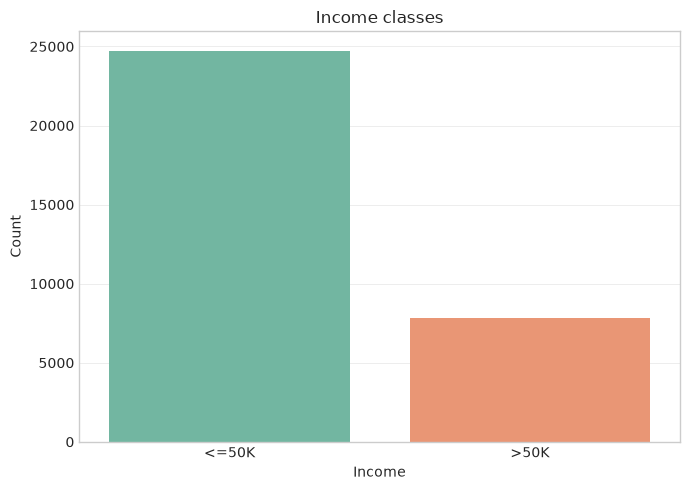

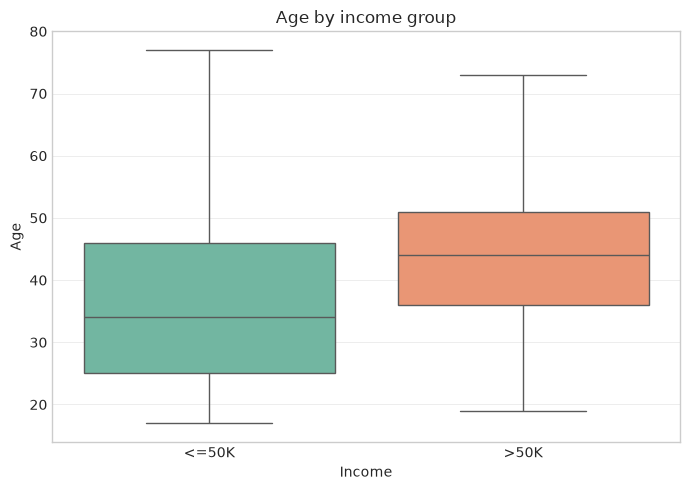

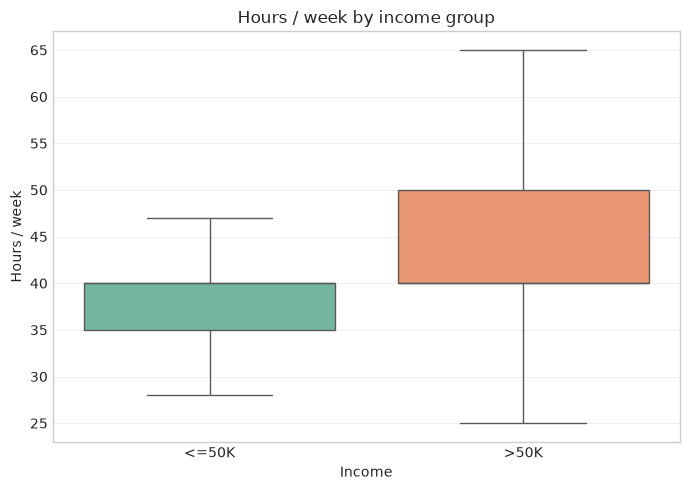

In [31]:
print("Income distribution:\n", train["income"].value_counts().sort_index())

income_order = ["<=50K", ">50K"]
income_palette = {"<=50K": "#66c2a5", ">50K": "#fc8d62"}

plt.figure(figsize=(7, 5))
sns.countplot(
    data=train,
    x="income",
    order=income_order,
    hue="income",
    hue_order=income_order,
    palette=income_palette,
    legend=False,
)
plt.title("Income classes")
plt.xlabel("Income")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

for column, label in [("age", "Age"), ("hours-per-week", "Hours / week")]:
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=train, x="income", y=column, order=income_order,
               hue="income", hue_order=income_order, palette=income_palette,
               legend=False, showfliers=False)
    plt.title(f"{label} by income group")
    plt.xlabel("Income")
    plt.ylabel(label)
    plt.tight_layout()
    plt.show()


### A few observations
- Most people earn <=50K.
- The >50K group is older on average.
- People earning >50K work more hours per week on average.


In [32]:
# Missing values are handled inside the model pipeline.


In [33]:
# Simple binary target
train["target"] = (train["income"] == ">50K").astype(int)
test["target"] = (test["income"] == ">50K").astype(int)

selected_features = [
    "age", "workclass", "education-num", "marital-status",
    "occupation", "relationship", "race", "sex",
    "hours-per-week"
]

X_train = train[selected_features]
y_train = train["target"]
X_test = test[selected_features]
y_test = test["target"]


## 2) Logistic regression model


Accuracy: 0.834

Classification report:

              precision    recall  f1-score   support

       <=50K       0.87      0.92      0.89     12435
        >50K       0.68      0.55      0.61      3846

    accuracy                           0.83     16281
   macro avg       0.78      0.74      0.75     16281
weighted avg       0.83      0.83      0.83     16281

Confusion matrix:
 [[11457   978]
 [ 1726  2120]]


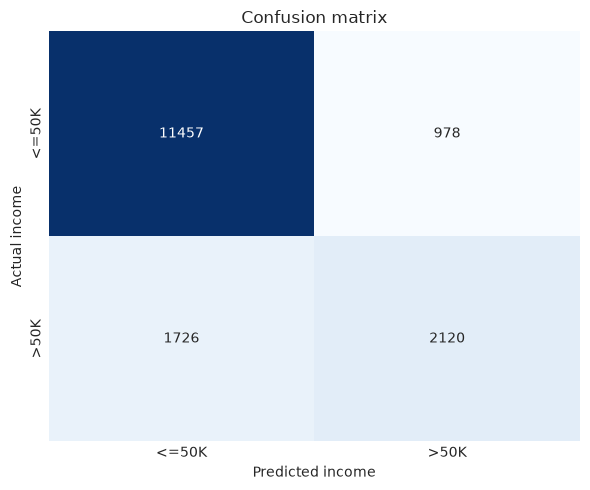

In [34]:
numeric_cols = ["age", "education-num", "hours-per-week"]
categorical_cols = [c for c in selected_features if c not in numeric_cols]

preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_cols
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_cols
    )
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, solver="liblinear"))
])

model.fit(X_train, y_train)
pred = model.predict(X_test)

accuracy = accuracy_score(y_test, pred)
print(f"Accuracy: {accuracy:.3f}")
print("\nClassification report:\n")
print(classification_report(y_test, pred, target_names=["<=50K", ">50K"]))

cm = confusion_matrix(y_test, pred)
print("Confusion matrix:\n", cm)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"],
)
plt.title("Confusion matrix")
plt.xlabel("Predicted income")
plt.ylabel("Actual income")
plt.tight_layout()
plt.show()
